# Team 11: feedback controls and final evaluation

**November 20, 2026.** We classify the current published appeal as affirmed (0) or reversed/vacated (1). This is not forecasting a future judgment. The notebook explains and verifies the completed experiments; saved final-test predictions are read only.

Review confirmation: **Yinkui Yu, November 19, 2026**, with no additional family corrections. Original provisional artifacts are preserved. The new reviewed release records the scope and source labels explicitly.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
HERE = Path.cwd()
if not (HERE / 'common.py').exists():
    HERE = HERE / 'experiments' / 'feedback_controls'
assert (HERE / 'common.py').exists(), 'Start in the repository or notebook directory.'
sys.path.insert(0, str(HERE))
from common import read, records, load_rows, SELECTED_C, SEEDS, digest
from modeling import estimator, scores
R = HERE / 'results'
F = HERE / 'final'
metrics = pd.DataFrame(read(R / 'metrics.json'))
final = pd.DataFrame(read(F / 'results/metrics.json'))
display(pd.DataFrame(read(R / 'completion_status.json')))

,planned_item,status
0,Human-reviewed release,Complete: user confirmation recorded; 320 deve...
1,Expanded FULL/MASKED and fixed C=1,Complete.
2,Five-seed matched removal,Complete for LR and LEGAL-BERT.
3,Mask components,"Complete 2x2 boundaries/matcher comparison, wi..."
4,First vs all chunks,Complete at C=.1 and C=1.
5,Quality sensitivity,"Complete dedup-only, mask-only, and combined r..."
6,Learning curves,Complete three nested-family seeds at 25/50/75...
7,Passage/error analysis,Complete eight fixed cases linked to all five ...
8,Reserved test and paired bootstrap,"Complete: 50 test records, 21 conditions, 5,00..."


## 1. Frozen data and review provenance

We exclude all 54 disputed B/C eligibility records and remove the approved Mann duplicate NY-6112018. The primary development replication keeps the earlier 279/42 split; deduplication and the final fit use 278 training rows. Test labels were fixed before any final predictions. Known same-family records stay together, but this is not a claim that every remaining source record is a unique decision. No labels, selected evidence quotes, case IDs or reviewer metadata enter the text features.

In [2]:
protocol = read(F / 'inputs/protocol.json')
review = read(F / 'inputs/human_review_confirmation.json')
for name, expected in protocol['sha256'].items():
    assert digest((F / 'inputs' / name).read_bytes()) == expected
manifest = pd.DataFrame(records(F / 'inputs/reviewed_manifest.jsonl'))
display(pd.crosstab(manifest.period, manifest.label).rename(columns={0:'Affirmed',1:'Reversed/vacated'}))
print('Review:', review['reviewer'], review['review_date'])
print(review['scope_interpretation'])
assert manifest.groupby('family_id').period.nunique().max() == 1

label,Affirmed,Reversed/vacated
period,,
test,34,16
train,181,97
validation,25,17


Review: Yinkui Yu 2026-11-19
Acceptance of the 320-row development and 50-candidate test review lists just supplied, with existing agreed labels and no additional family corrections; this interpretation was stated to the user in chat.


## 2. Preprocessing and matched interventions

FULL removes publication material using the inherited batch-specific cleaner. MASKED uses the exact earlier A versus B/C policies. Each random control deletes exactly the same number of whitespace-delimited words as MASKED, with seeds 11, 23, 37, 51 and 71. This matches word quantity, **not** semantic content or WordPiece-token counts. REVISED applies the approved training-audit corrections uniformly, without case-ID exceptions. Some residual outcome language remains; this is a sensitivity experiment, not a certified outcome-free representation.

In [3]:
variants = records(HERE / 'inputs/variants.jsonl')
quality = records(HERE / 'inputs/quality_v1/variants.jsonl')
for row in variants:
    for seed in SEEDS:
        assert len(row['texts'][f'RANDOM_{seed}'].split()) == len(row['texts']['MASKED'].split())
for row in quality:
    for seed in SEEDS:
        assert len(row['texts'][f'REVISED_RANDOM_{seed}'].split()) == len(row['texts']['REVISED'].split())
display(pd.DataFrame(read(R / 'component_retention.json')))
print('All development random-removal budgets verified.')

,variant,cases_changed_from_OLD,words_removed_total,empty_cases
0,OLD,0,15388,0
1,BOUNDARY_ONLY,74,13055,0
2,RULE_ONLY,0,15388,0
3,COMBINED,74,13055,0
4,REVISED,106,11536,0


All development random-removal budgets verified.


## 3. Two-class masking audit

Four flagged training opinions (two from each class) motivated the frozen revision. Four validation opinions, also two per class, were checked afterward without retuning. The audit distinguishes original judicial reasoning, prior rulings and citations from the current disposition. It records failures instead of claiming a perfect mask.

In [4]:
audit = read(R / 'two_class_mask_audit.json')
display(pd.DataFrame(audit['cases'])[['case_id','period','label','preserved_kind','preserved_in_original_mask','preserved_in_revision','technical_review_note']])
print('Residual issues:', *audit['unresolved_findings'], sep='\n- ')

,case_id,period,label,preserved_kind,preserved_in_original_mask,preserved_in_revision,technical_review_note
0,NY-4509516,train,0,quoted earlier rule,False,True,Restore the cited burden rule. Current merits ...
1,NY-5950295,train,0,quoted general rule,False,True,The previous mask joined the quoted rule to we...
2,NY-4427636,train,1,procedural history,False,True,The revision restores history lost at the LLC....
3,NY-5980564,train,1,previous-decision citation,False,True,"The long conclusion contained citations, not 1..."
4,NY-8511862,validation,0,reasoning,True,True,"Facts, the historical denial and failure-of-pr..."
5,NY-6459053,validation,0,prior ruling,True,True,Prior ruling and notice reasoning survive; the...
6,NY-5304378,validation,1,reasoning,True,True,Residual cue: generic the court should have gr...
7,NY-5957906,validation,1,reasoning,True,True,The repeated explicit result is removed; one r...


Residual issues:
- NY-5304378 retains generic court-should-have wording.
- Previously audited NY-9301972 retains unanimously affirmed in original and revised text.
- Current-result and reasoning clauses can be inseparable under rule-based deletion.


## 4. Models, training-only choices and frozen encoder

LR and SVM use training-fitted unigram/bigram TF-IDF (`min_df=2`, maximum 30,000 features) with balanced class weights. The previous training-family CV selected C=10 for both lexical models and C=0.1 for LEGAL-BERT LR. Those settings are fixed across primary text variants; C=1 is a separate sensitivity check.

The pinned frozen LEGAL-BERT checkpoint is processed in non-overlapping chunks of 510 content tokens plus special tokens. We average the last hidden layer over content tokens, excluding padding and special tokens, then combine chunks with token-count weights. Standardization is fitted only on training vectors. No encoder fine-tuning was done. First-chunk-only uses the same tokenization and classifier settings.

In [5]:
index = read(R / 'embeddings/index.json')
for name, expected in index['sha256'].items():
    assert digest((R / 'embeddings' / name).read_bytes()) == expected
print(index['settings']['encoder'])
print('Fixed C:', SELECTED_C)
display(pd.DataFrame(read(R / 'length_statistics.json')).query("variant in ['FULL','MASKED','REVISED']"))

{'encoder': 'nlpaueb/legal-bert-base-uncased', 'revision': '15b570cbf88259610b082a167dacc190124f60f6', 'tokenizer': 'BertTokenizer', 'use_fast': False, 'content_tokens': 510, 'overlap': 0, 'padding_side': 'right', 'batch_size_chunks': 4, 'hidden_size': 768, 'threads': 4, 'pooling': 'last hidden layer; sum content-token vectors over all nonoverlapping chunks and divide by total content tokens; exclude special tokens and padding', 'protocol_version': 1}
Fixed C: {'TFIDF_LR': 10.0, 'TFIDF_SVM': 10.0, 'LEGAL_BERT_LR': 0.1}


,period,variant,n,tokens_median,tokens_max,more_than_one_chunk,chunks_total
0,train,FULL,279,641.0,2954,188,516
1,train,MASKED,279,589.0,2954,172,491
2,train,REVISED,279,602.0,2954,176,498
8,validation,FULL,42,693.0,2617,36,93
9,validation,MASKED,42,642.0,2594,33,88
10,validation,REVISED,42,648.5,2594,33,90


## 5. Demonstrate the fit/evaluate boundary

This cell refits a development LR example and checks it against the completed run. Vocabulary and IDF see only training text. The full experiment runner uses the same estimator function for each fixed intervention. Reproduction commands are in the README; feature extraction is cached, and **final evaluation has an overwrite guard**.

In [6]:
rows = load_rows()
train = np.array([r['period']=='train' for r in rows])
y = np.array([r['label'] for r in rows])
texts = np.array([r['texts']['MASKED'] for r in rows], dtype=object)
model = estimator('TFIDF_LR', 10.0).fit(texts[train], y[train])
prediction = model.predict(texts[~train])
example = scores(y[~train], prediction)
saved = metrics.query("experiment=='primary' and model=='TFIDF_LR' and variant=='MASKED'").iloc[0]
assert example['confusion_matrix'] == saved.confusion_matrix
print(example)

{'accuracy': 0.5714285714285714, 'balanced_accuracy': 0.5364705882352941, 'macro_f1': 0.5333333333333333, 'recall_0': 0.72, 'recall_1': 0.35294117647058826, 'confusion_matrix': [[18, 7], [11, 6]]}

## 6. Reproduced development results

All eight original FULL/MASKED model conditions reproduce their saved class predictions exactly. Tiny embedding differences across runtime environments are recorded, rather than described as bit-identical. The validation set has 25 label-0 and 17 label-1 cases, so accuracy and balanced accuracy differ.

In [7]:
columns = ['model','variant','C','accuracy','balanced_accuracy','macro_f1','recall_0','recall_1','confusion_matrix']
display(metrics.query("experiment=='primary' and variant in ['FULL','MASKED']")[columns])
display(pd.DataFrame(read(R / 'verification.json')['reference_prediction_reproduction']))

,model,variant,C,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
0,Majority,FULL,NaN,0.595238,0.500000,0.373134,1.00,0.000000,"[[25, 0], [17, 0]]"
1,Majority,MASKED,NaN,0.595238,0.500000,0.373134,1.00,0.000000,"[[25, 0], [17, 0]]"
2,TFIDF_LR,FULL,10.0,0.809524,0.821176,0.807780,0.76,0.882353,"[[19, 6], [2, 15]]"
3,TFIDF_LR,MASKED,10.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"
68,TFIDF_SVM,FULL,10.0,0.880952,0.881176,0.877551,0.88,0.882353,"[[22, 3], [2, 15]]"
69,TFIDF_SVM,MASKED,10.0,0.547619,0.507059,0.499687,0.72,0.294118,"[[18, 7], [12, 5]]"
76,LEGAL_BERT_LR,FULL,0.1,0.880952,0.881176,0.877551,0.88,0.882353,"[[22, 3], [2, 15]]"
77,LEGAL_BERT_LR,MASKED,0.1,0.476190,0.503529,0.475000,0.36,0.647059,"[[9, 16], [6, 11]]"


,model,variant,different_predictions
0,Majority,FULL,0
1,Majority,MASKED,0
2,TFIDF_LR,FULL,0
3,TFIDF_LR,MASKED,0
4,TFIDF_SVM,FULL,0
5,TFIDF_SVM,MASKED,0
6,LEGAL_BERT_LR,FULL,0
7,LEGAL_BERT_LR,MASKED,0


## 7. Instructor feedback: matched random removal for LEGAL-BERT

We independently refit each text variant at the same fixed C, on identical cases. Report all five seeds, not the best seed. The averages below summarize five models, not an ensemble. Both LR and LEGAL-BERT retain substantially more validation performance under random removal than under targeted masking. This argues against word quantity alone explaining the drop, but does not prove that only outcome cues matter.

,model,variant,C,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
4,TFIDF_LR,RANDOM_11,10.0,0.714286,0.703529,0.703529,0.76,0.647059,"[[19, 6], [6, 11]]"
5,TFIDF_LR,RANDOM_23,10.0,0.714286,0.703529,0.703529,0.76,0.647059,"[[19, 6], [6, 11]]"
6,TFIDF_LR,RANDOM_37,10.0,0.785714,0.791765,0.782634,0.76,0.823529,"[[19, 6], [3, 14]]"
7,TFIDF_LR,RANDOM_51,10.0,0.714286,0.703529,0.703529,0.76,0.647059,"[[19, 6], [6, 11]]"
8,TFIDF_LR,RANDOM_71,10.0,0.809524,0.811765,0.805556,0.80,0.823529,"[[20, 5], [3, 14]]"
78,LEGAL_BERT_LR,RANDOM_11,0.1,0.738095,0.742353,0.734330,0.72,0.764706,"[[18, 7], [4, 13]]"
79,LEGAL_BERT_LR,RANDOM_23,0.1,0.738095,0.742353,0.734330,0.72,0.764706,"[[18, 7], [4, 13]]"
80,LEGAL_BERT_LR,RANDOM_37,0.1,0.738095,0.751765,0.736752,0.68,0.823529,"[[17, 8], [3, 14]]"
81,LEGAL_BERT_LR,RANDOM_51,0.1,0.738095,0.732941,0.730612,0.76,0.705882,"[[19, 6], [5, 12]]"
82,LEGAL_BERT_LR,RANDOM_71,0.1,0.809524,0.811765,0.805556,0.80,0.823529,"[[20, 5], [3, 14]]"


,model,experiment,seeds,accuracy_mean,balanced_accuracy_mean,macro_f1_mean,accuracy_sample_sd,balanced_accuracy_sample_sd,macro_f1_sample_sd
0,TFIDF_LR,primary,"[11, 23, 37, 51, 71]",0.747619,0.742824,0.739755,0.046413,0.054268,0.050262
4,LEGAL_BERT_LR,primary,"[11, 23, 37, 51, 71]",0.752381,0.756235,0.748316,0.031944,0.031747,0.032073


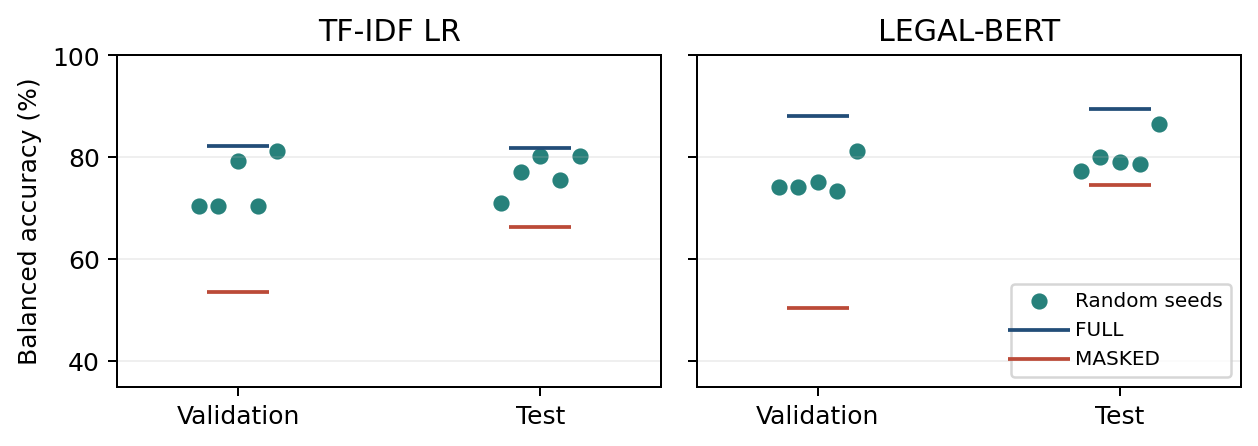

In [8]:
display(metrics.query("experiment=='primary' and variant.str.startswith('RANDOM')", engine='python')[columns])
display(pd.DataFrame(read(R / 'seed_summaries.json')).query("experiment=='primary'"))
display(Image(filename=str(R / 'figures/controls.png')))

## 8. Same fitted classifier diagnostic

A separately fitted FULL classifier and MASKED classifier can disagree even when a particular case has identical text. Here the FULL-fitted vectorizer/scaler and coefficients remain fixed while inputs change. This isolates input sensitivity more directly, but creates a distribution shift; it is not the main model ranking.

In [9]:
display(metrics.query("experiment=='same_fitted_FULL' and variant in ['FULL','MASKED']")[columns])
links = read(R / 'audit_prediction_links.json')
display(pd.DataFrame([{'case_id':r['case_id'],'mode':r['experiment'],**r['predictions']} for r in links if r['model']=='LEGAL_BERT_LR']))

,model,variant,C,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
11,TFIDF_LR,FULL,10.0,0.809524,0.821176,0.807780,0.76,0.882353,"[[19, 6], [2, 15]]"
12,TFIDF_LR,MASKED,10.0,0.571429,0.527059,0.517857,0.76,0.294118,"[[19, 6], [12, 5]]"
85,LEGAL_BERT_LR,FULL,0.1,0.880952,0.881176,0.877551,0.88,0.882353,"[[22, 3], [2, 15]]"
86,LEGAL_BERT_LR,MASKED,0.1,0.619048,0.557647,0.533333,0.88,0.235294,"[[22, 3], [13, 4]]"


,case_id,mode,FULL,MASKED,RANDOM_11,RANDOM_23,RANDOM_37,RANDOM_51,RANDOM_71
0,NY-4929051,primary,1,0,1,0,1,0,1
1,NY-4929051,same_fitted_FULL,1,1,1,1,1,1,1
2,NY-5304378,primary,1,0,1,1,1,0,1
3,NY-5304378,same_fitted_FULL,1,0,1,1,1,1,1
4,NY-8511862,primary,1,1,0,1,1,0,0
5,NY-8511862,same_fitted_FULL,1,1,0,0,1,1,1
6,NY-6459053,primary,0,1,1,0,1,0,0
7,NY-6459053,same_fitted_FULL,0,0,1,0,0,0,0
8,NY-5957906,primary,1,0,0,1,1,1,1
9,NY-5957906,same_fitted_FULL,1,0,0,1,1,1,1


## 9. Link changed predictions to passage evidence

The eight cases were fixed in the earlier audit. We recheck all 22 quoted evidence spans and calculate how much of each quote each random draw removes. These are descriptive case comparisons, not causal explanations of a model's internal reasoning. In NY-9301972, FULL equals MASKED and retains an affirmance cue: its refitted-classifier flip disappears with a fixed fitted classifier. NY-5304378 and NY-5957906 still flip under fixed-classifier masking while most random draws remain correct. NY-4929051 behaves differently across refitting modes, illustrating a training effect.

In [10]:
display(pd.DataFrame(read(R / 'prediction_changes.json')))
for case in [r for r in links if r['model']=='LEGAL_BERT_LR' and r['experiment']=='primary']:
    display(Markdown('**'+case['case_id']+'** — '+case['interpretation']))
    display(pd.DataFrame([{'quote':e['quote'], **e['fraction_of_quote_words_removed_by_seed']} for e in case['evidence']]))

,model,variant,changed,correct_to_wrong,wrong_to_correct,correct_both,wrong_both
0,TFIDF_LR,MASKED,10,10,0,24,8
1,TFIDF_LR,RANDOM_11,4,4,0,30,8
2,TFIDF_LR,RANDOM_23,4,4,0,30,8
3,TFIDF_LR,RANDOM_37,1,1,0,33,8
4,TFIDF_LR,RANDOM_51,4,4,0,30,8
5,TFIDF_LR,RANDOM_71,2,1,1,33,7
6,TFIDF_SVM,MASKED,14,14,0,23,5
7,LEGAL_BERT_LR,MASKED,21,19,2,18,3
8,LEGAL_BERT_LR,RANDOM_11,8,7,1,30,4
9,LEGAL_BERT_LR,RANDOM_23,8,7,1,30,4


**NY-4929051** — Long procedural history; removed opening orders also describe prior rulings; retained merits and ancillary motion disposition.

,quote,11,23,37,51,71
0,"On the merits, we find that Findlay failed to ...",0.0,0.0,0.0,0.0,0.0
1,"By order entered July 16, 2020, the court gran...",0.0,1.0,1.0,0.0,0.0
2,Motion for an enlargement of time to file and ...,1.0,0.0,0.0,0.0,0.0


**NY-5304378** — Retained law-office-failure and merits reasoning; explicit evaluative wording remains. Generic court-should-have language is missed by the revised B/C rule.

,quote,11,23,37,51,71
0,the Supreme Court improvidently exercised its ...,0.0,0.0,0.0,0.0,0.0
1,"Moreover, the plaintiff demonstrated that he h...",0.0,0.0,0.0,0.0,0.0
2,"In an order entered March 8, 2018, the Supreme...",0.0,0.0,0.0,0.0,0.0


**NY-8511862** — Denial of defense summary judgment is affirmed; retained reasoning concerns failure of defendant proof, not a plaintiff victory on liability.

... (7 outputs left out)

**NY-4894160** — Contractor duty and creation-of-hazard reasoning remains; original MASKED truncates a trailing citation.

,quote,11,23,37,51,71
0,"it failed to affirmatively demonstrate, prima ...",0.0,0.0,0.0,0.0,0.0
1,"The Supreme Court denied All Jersey's motion, ...",1.0,1.0,0.0,0.0,0.0
2,"Ctr. , 64 NY2d 851, 853 [1985]",0.0,0.0,0.0,1.0,0.0


**NY-6476214** — Long correct example; evaluative statement that the motion should have been denied remains. All chunks were processed.

,quote,11,23,37,51,71
0,"In light of these unresolved issues, defendant...",0.0,0.0,0.0,0.0,0.0
1,Despite Supreme Court's suggestion to the cont...,0.0,0.0,0.0,0.0,0.0


## 10. C=1 and controlled masking components

The 2×2 comparison changes sentence boundaries and the outcome matcher separately, keeping cases and LR C=10 fixed. On this corpus the matcher-only change produces exactly the old texts; combined equals boundary-only. All four targeted conditions have the same validation predictions, despite retention differences. This is evidence that a preprocessing retention improvement need not produce a measurable classifier gain.

In [11]:
display(metrics.query("experiment=='C1_sensitivity'")[columns])
display(metrics.query("experiment=='components' and not variant.str.contains('RANDOM')", engine='python')[columns])

,model,variant,C,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
9,TFIDF_LR,FULL,1.0,0.714286,0.722353,0.711670,0.68,0.764706,"[[17, 8], [4, 13]]"
10,TFIDF_LR,MASKED,1.0,0.571429,0.564706,0.562500,0.60,0.529412,"[[15, 10], [8, 9]]"
70,TFIDF_SVM,FULL,1.0,0.833333,0.841176,0.830937,0.80,0.882353,"[[20, 5], [2, 15]]"
71,TFIDF_SVM,MASKED,1.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"
83,LEGAL_BERT_LR,FULL,1.0,0.904762,0.901176,0.901176,0.92,0.882353,"[[23, 2], [2, 15]]"
84,LEGAL_BERT_LR,MASKED,1.0,0.476190,0.503529,0.475000,0.36,0.647059,"[[9, 16], [6, 11]]"


,model,variant,C,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
32,TFIDF_LR,OLD,10.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"
38,TFIDF_LR,BOUNDARY_ONLY,10.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"
44,TFIDF_LR,RULE_ONLY,10.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"
50,TFIDF_LR,COMBINED,10.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"


## 11. Approved quality corrections

We separately test removing the Mann duplicate, refining the mask, and both. Deduplication alone does not change original FULL/MASKED predictions here. REVISED preserves some previously lost context but is not uniformly more accurate. Accuracy was not used to decide whether a clearly mistaken deletion should be repaired.

In [12]:
display(metrics.query("experiment in ['dedup_only','mask_only','dedup_and_mask'] and not variant.str.contains('RANDOM')", engine='python')[['experiment','n_train']+columns])

,experiment,n_train,model,variant,C,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
18,dedup_only,278,TFIDF_LR,FULL,10.0,0.809524,0.821176,0.807780,0.76,0.882353,"[[19, 6], [2, 15]]"
19,dedup_only,278,TFIDF_LR,MASKED,10.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"
20,mask_only,279,TFIDF_LR,REVISED,10.0,0.547619,0.516471,0.514303,0.68,0.352941,"[[17, 8], [11, 6]]"
21,dedup_and_mask,278,TFIDF_LR,REVISED,10.0,0.547619,0.516471,0.514303,0.68,0.352941,"[[17, 8], [11, 6]]"
72,dedup_only,278,TFIDF_SVM,FULL,10.0,0.880952,0.881176,0.877551,0.88,0.882353,"[[22, 3], [2, 15]]"
73,dedup_only,278,TFIDF_SVM,MASKED,10.0,0.547619,0.507059,0.499687,0.72,0.294118,"[[18, 7], [12, 5]]"
74,mask_only,279,TFIDF_SVM,REVISED,10.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"
75,dedup_and_mask,278,TFIDF_SVM,REVISED,10.0,0.571429,0.536471,0.533333,0.72,0.352941,"[[18, 7], [11, 6]]"
92,dedup_only,278,LEGAL_BERT_LR,FULL,0.1,0.880952,0.881176,0.877551,0.88,0.882353,"[[22, 3], [2, 15]]"
93,dedup_only,278,LEGAL_BERT_LR,MASKED,0.1,0.476190,0.503529,0.475000,0.36,0.647059,"[[9, 16], [6, 11]]"


## 12. Length ablation and learning curves

First-chunk-only does not show a consistent disadvantage on this small validation set; it can retain opening dispositions in FULL. The eight longest examples contain five reversals, so length and class are confounded. Nested learning curves sample whole training families at 25/50/75/100%, with three fixed seeds and unchanged validation. They do not support a monotonic improvement claim.

In [13]:
display(metrics.query("experiment=='chunk_ablation'")[columns])
display(pd.DataFrame(read(R / 'chunk_length_groups.json')))
display(metrics.query("experiment=='learning_curve'").groupby(['model','fraction']).agg(n_train=('n_train','mean'),mean_BA=('balanced_accuracy','mean'),sd_BA=('balanced_accuracy','std')))

,model,variant,C,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
106,LEGAL_BERT_LR,FULL,0.1,0.880952,0.881176,0.877551,0.88,0.882353,"[[22, 3], [2, 15]]"
107,LEGAL_BERT_LR,FULL_FIRST,0.1,0.880952,0.890588,0.879241,0.84,0.941176,"[[21, 4], [1, 16]]"
108,LEGAL_BERT_LR,MASKED,0.1,0.476190,0.503529,0.475000,0.36,0.647059,"[[9, 16], [6, 11]]"
109,LEGAL_BERT_LR,MASKED_FIRST,0.1,0.523810,0.543529,0.523810,0.44,0.647059,"[[11, 14], [6, 11]]"
110,LEGAL_BERT_LR,FULL,1.0,0.904762,0.901176,0.901176,0.92,0.882353,"[[23, 2], [2, 15]]"
111,LEGAL_BERT_LR,FULL_FIRST,1.0,0.904762,0.901176,0.901176,0.92,0.882353,"[[23, 2], [2, 15]]"
112,LEGAL_BERT_LR,MASKED,1.0,0.476190,0.503529,0.475000,0.36,0.647059,"[[9, 16], [6, 11]]"
113,LEGAL_BERT_LR,MASKED_FIRST,1.0,0.547619,0.563529,0.547362,0.48,0.647059,"[[12, 13], [6, 11]]"


,full_chunks_group,variant,n,class_0,class_1,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
0,one,FULL,6,5,1,0.833333,0.900000,0.777778,0.800000,1.000000,"[[4, 1], [0, 1]]"
1,one,FULL_FIRST,6,5,1,0.833333,0.900000,0.777778,0.800000,1.000000,"[[4, 1], [0, 1]]"
2,one,MASKED,6,5,1,0.333333,0.600000,0.333333,0.200000,1.000000,"[[1, 4], [0, 1]]"
3,one,MASKED_FIRST,6,5,1,0.500000,0.700000,0.485714,0.400000,1.000000,"[[2, 3], [0, 1]]"
4,two,FULL,28,17,11,0.892857,0.895722,0.889328,0.882353,0.909091,"[[15, 2], [1, 10]]"
5,two,FULL_FIRST,28,17,11,0.928571,0.941176,0.927083,0.882353,1.000000,"[[15, 2], [0, 11]]"
6,two,MASKED,28,17,11,0.464286,0.494652,0.463602,0.352941,0.636364,"[[6, 11], [4, 7]]"
7,two,MASKED_FIRST,28,17,11,0.535714,0.569519,0.535121,0.411765,0.727273,"[[7, 10], [3, 8]]"
8,three_plus,FULL,8,3,5,0.875000,0.900000,0.873016,1.000000,0.800000,"[[3, 0], [1, 4]]"
9,three_plus,FULL_FIRST,8,3,5,0.750000,0.733333,0.733333,0.666667,0.800000,"[[2, 1], [1, 4]]"


n_train   mean_BA     sd_BA
model         fraction                                
LEGAL_BERT_LR 0.25       69.666667  0.530980  0.056622
              0.50      140.000000  0.550980  0.040367
              0.75      210.000000  0.510588  0.054258
              1.00      279.000000  0.503529  0.000000
TFIDF_LR      0.25       69.666667  0.512157  0.056938
              0.50      140.000000  0.505882  0.020613
              0.75      210.000000  0.545882  0.026016
              1.00      279.000000  0.536471  0.000000

## 13. Development uncertainty

We resample validation **families**, preserving pairing across models and conditions, 5,000 times. These percentile intervals are descriptive because validation has been used repeatedly. Seed SD measures deletion randomness; bootstrap intervals measure variation in sampled families conditional on the fitted models. Neither includes uncertainty from relabeling or alternate training sets.

In [14]:
intervals = pd.DataFrame(read(R / 'paired_intervals.json'))
display(intervals.query("metric=='balanced_accuracy'")[[ 'comparison','difference','lower','upper']])

,comparison,difference,lower,upper
1,TFIDF_LR FULL - MASKED,0.284706,0.157895,0.411765
4,TFIDF_LR revised - original mask,-0.020000,-0.066667,0.000000
7,TFIDF_LR dedup mask - original mask,0.000000,0.000000,0.000000
10,TFIDF_LR primary mean random - mask,0.206353,0.109719,0.311542
13,TFIDF_LR same_fitted_FULL mean random - mask,0.209882,0.114867,0.306944
16,TFIDF_LR mask_only mean random - mask,0.248000,0.138327,0.365694
19,TFIDF_LR dedup_and_mask mean random - mask,0.244000,0.134064,0.361011
22,TFIDF_SVM FULL - MASKED,0.374118,0.235264,0.517857
25,TFIDF_SVM revised - original mask,0.029412,0.000000,0.100000
28,TFIDF_SVM dedup mask - original mask,0.000000,0.000000,0.000000


## 14. Reserved test: frozen choices and one evaluation

After Yinkui Yu's review confirmation, we froze 50 test records and fit on 278 training records only; the 42 validation records were not added to training. Fixed C, seeds, masks and comparisons were recorded before final predictions. Primary FULL/MASKED and matched controls are separate from the secondary REVISED condition. The test has now been evaluated and must not be reused for tuning. Reading these saved outputs is not a new test run.

,model,variant,C,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1,confusion_matrix
0,Majority,FULL,NaN,0.68,0.500000,0.404762,1.000000,0.0000,"[[34, 0], [16, 0]]"
1,Majority,MASKED,NaN,0.68,0.500000,0.404762,1.000000,0.0000,"[[34, 0], [16, 0]]"
2,TFIDF_LR,FULL,10.0,0.82,0.818015,0.802198,0.823529,0.8125,"[[28, 6], [3, 13]]"
3,TFIDF_LR,MASKED,10.0,0.70,0.663603,0.660787,0.764706,0.5625,"[[26, 8], [7, 9]]"
4,TFIDF_LR,REVISED,10.0,0.70,0.663603,0.660787,0.764706,0.5625,"[[26, 8], [7, 9]]"
5,TFIDF_LR,RANDOM_11,10.0,0.74,0.709559,0.706015,0.794118,0.6250,"[[27, 7], [6, 10]]"
6,TFIDF_LR,RANDOM_23,10.0,0.78,0.772059,0.758242,0.794118,0.7500,"[[27, 7], [4, 12]]"
7,TFIDF_LR,RANDOM_37,10.0,0.80,0.803309,0.782986,0.794118,0.8125,"[[27, 7], [3, 13]]"
8,TFIDF_LR,RANDOM_51,10.0,0.78,0.755515,0.751244,0.823529,0.6875,"[[28, 6], [5, 11]]"
9,TFIDF_LR,RANDOM_71,10.0,0.80,0.803309,0.782986,0.794118,0.8125,"[[27, 7], [3, 13]]"


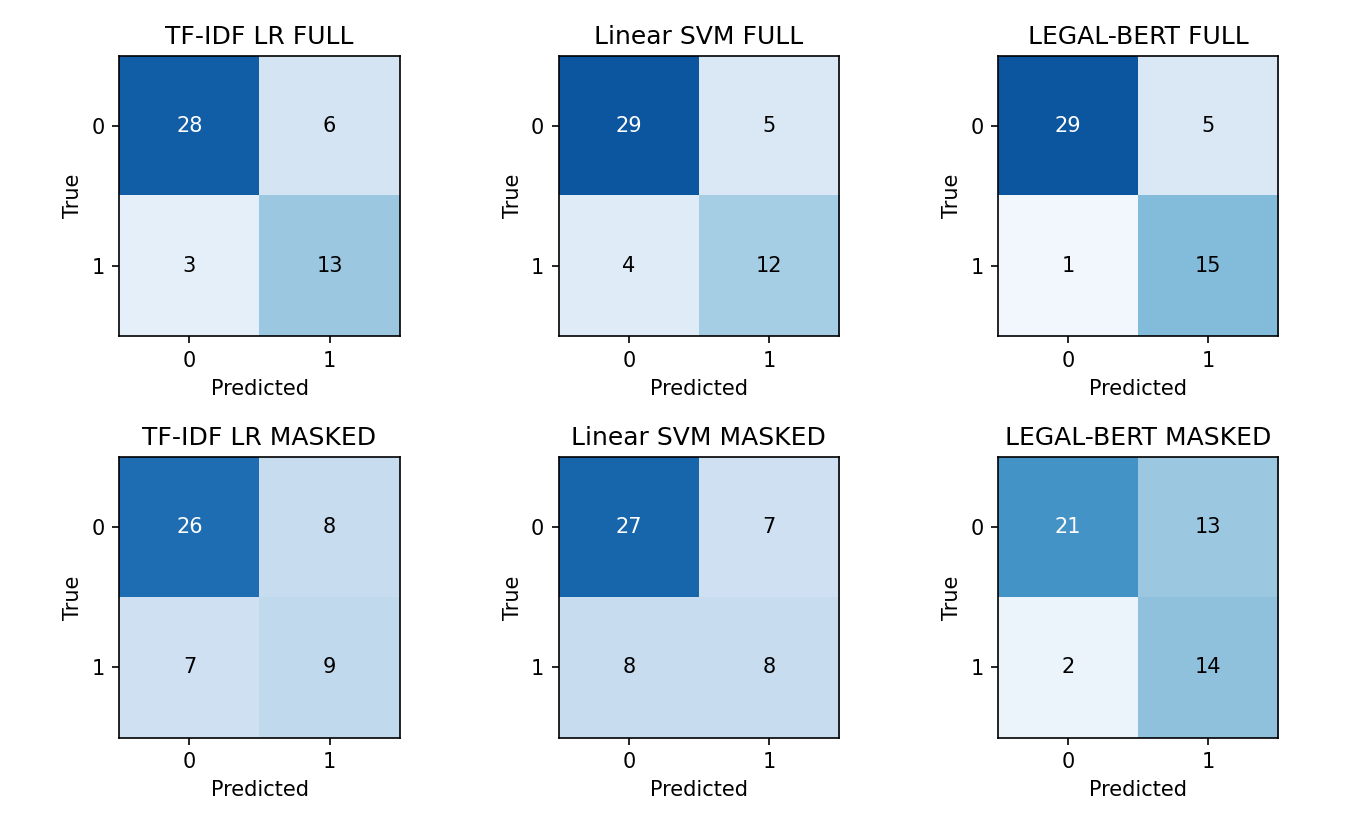

In [15]:
v = read(F / 'results/verification.json')
for name, expected in v['output_sha256'].items():
    assert digest((F / 'results' / name).read_bytes()) == expected
assert digest((F / 'inputs/protocol.json').read_bytes()) == v['protocol_sha256']
test_preds = pd.DataFrame(records(F / 'results/predictions.jsonl'))
for run, part in test_preds.groupby('run_id'):
    actual = scores(part.label.to_numpy(), part.prediction.to_numpy())
    expected = final.set_index('run_id').loc[run]
    assert actual['confusion_matrix'] == expected.confusion_matrix
display(final[columns])
display(Image(filename=str(R / 'figures/test_confusions.png')))

## 15. Paired final-test uncertainty

All models use the same 50 test cases. Confidence intervals resample whole test families, with the same draws across conditions. They remain conditional on this selected published-opinion sample, its accepted labels, the fitted training set, and the known masking limitations. Multiple comparisons are exploratory; no best seed or post-test parameter was selected.

In [16]:
display(pd.DataFrame(read(F / 'results/intervals.json')).query("metric=='balanced_accuracy'"))
display(pd.DataFrame(read(F / 'results/paired_intervals.json')).query("metric=='balanced_accuracy'"))

,run_id,metric,value,lower,upper
1,Majority:FULL,balanced_accuracy,0.500000,0.500000,0.500000
4,Majority:MASKED,balanced_accuracy,0.500000,0.500000,0.500000
7,TFIDF_LR:FULL,balanced_accuracy,0.818015,0.692708,0.924632
10,TFIDF_LR:MASKED,balanced_accuracy,0.663603,0.511029,0.799536
13,TFIDF_LR:REVISED,balanced_accuracy,0.663603,0.511029,0.799536
16,TFIDF_LR:RANDOM_11,balanced_accuracy,0.709559,0.562485,0.839917
19,TFIDF_LR:RANDOM_23,balanced_accuracy,0.772059,0.638889,0.893048
22,TFIDF_LR:RANDOM_37,balanced_accuracy,0.803309,0.675000,0.912500
25,TFIDF_LR:RANDOM_51,balanced_accuracy,0.755515,0.616228,0.881462
28,TFIDF_LR:RANDOM_71,balanced_accuracy,0.803309,0.675000,0.912500


,model,comparison,metric,difference,lower,upper
1,TFIDF_LR,FULL - MASKED,balanced_accuracy,0.154412,0.045956,0.277579
4,TFIDF_LR,REVISED - MASKED,balanced_accuracy,0.000000,0.000000,0.000000
7,TFIDF_LR,mean RANDOM - MASKED,balanced_accuracy,0.105147,0.027619,0.202386
10,TFIDF_SVM,FULL - MASKED,balanced_accuracy,0.154412,0.047619,0.280749
13,TFIDF_SVM,REVISED - MASKED,balanced_accuracy,-0.014706,-0.046875,0.000000
16,LEGAL_BERT_LR,FULL - MASKED,balanced_accuracy,0.148897,0.005913,0.290216
19,LEGAL_BERT_LR,REVISED - MASKED,balanced_accuracy,-0.014706,-0.067568,0.032258
22,LEGAL_BERT_LR,mean RANDOM - MASKED,balanced_accuracy,0.057353,-0.070594,0.193058


## 16. Conclusions and next steps

The controlled experiments test information loss, classifier refitting, preprocessing components, duplicate weighting and chunk coverage separately. The strongest development finding is that targeted masking hurts more than quantity-matched random removal. The passage audit shows why this must be described as sensitivity to a mix of outcome cues and legal reasoning.

On the final test, masked LR, SVM and LEGAL-BERT all have **70% accuracy**, but balanced accuracies differ: **66.36%, 64.71%, 74.63%**. BERT recalls 14/16 reversals but only 21/34 affirmances. Its mean random-minus-mask advantage is **5.74 points**, with a paired interval **[-7.06, 19.31]**; this smaller test gap does not establish the large development effect as stable. LR's gap is **10.51 points [2.76, 20.24]**. FULL remains easier, and no definitive model ranking follows from this small selected test set.

Next: document these differing development/test patterns, sample-selection and residual-cue limitations, and finish the project presentation. Do not tune on this test set. Any future mask redesign or new model would need new held-out data for independent evaluation. The original provisional releases remain historical artifacts; the reviewed final release carries the new confirmation record.